First five rows:
   Hours Studied  Previous Scores Extracurricular Activities  Sleep Hours  \
0              7               99                        Yes            9   
1              4               82                         No            4   
2              8               51                        Yes            7   
3              5               52                        Yes            5   
4              7               75                         No            8   

   Sample Question Papers Practiced  Performance Index  
0                                 1               91.0  
1                                 2               65.0  
2                                 2               45.0  
3                                 2               36.0  
4                                 5               66.0  

Dataset shape: (10000, 6)

Missing values:
Hours Studied                       0
Previous Scores                     0
Extracurricular Activities          0
Sleep Hours         

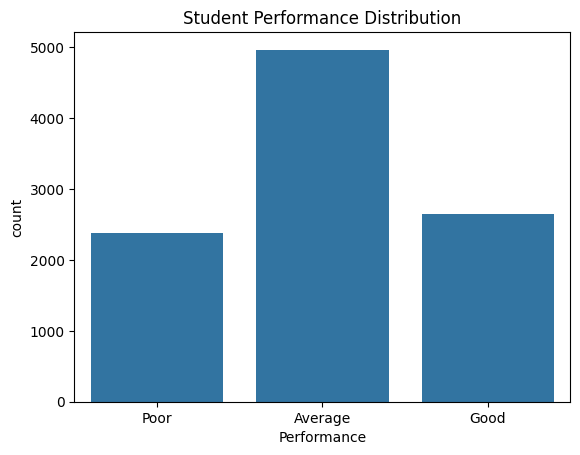


K = 3
Accuracy: 0.904
Precision: 0.9078
Recall: 0.899
F1 Score: 0.9032

K = 5
Accuracy: 0.9155
Precision: 0.9184
Recall: 0.9119
F1 Score: 0.915

K = 7
Accuracy: 0.917
Precision: 0.9214
Recall: 0.9122
F1 Score: 0.9166

Best K: 7

Confusion Matrix:
[[424  52   0]
 [ 31 924  38]
 [  0  45 486]]


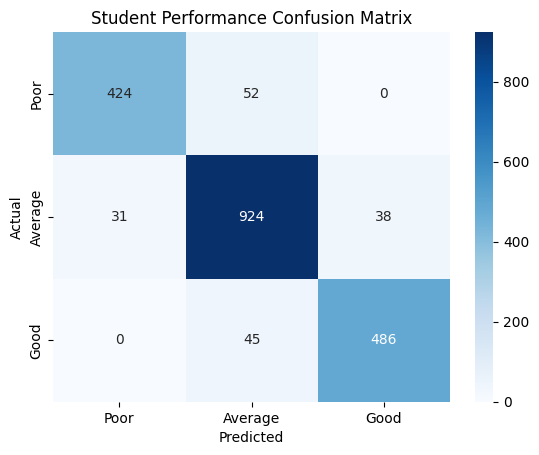


Classification Report:
              precision    recall  f1-score   support

     Average       0.90      0.93      0.92       993
        Good       0.93      0.92      0.92       531
        Poor       0.93      0.89      0.91       476

    accuracy                           0.92      2000
   macro avg       0.92      0.91      0.92      2000
weighted avg       0.92      0.92      0.92      2000

Predicted Performance: Good


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

df = pd.read_csv("Student_Performance.csv")

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

df["Performance"] = pd.cut(
    df["Performance Index"],
    bins=[0, 40, 70, 101],
    labels=["Poor", "Average", "Good"],
    right=False
)

print("\nPerformance distribution:")
print(df["Performance"].value_counts())

sns.countplot(data=df, x="Performance", order=["Poor", "Average", "Good"])
plt.title("Student Performance Distribution")
plt.show()

X = df.drop(["Performance Index", "Performance"], axis=1)
y = df["Performance"]

X = pd.get_dummies(X, columns=["Extracurricular Activities"], drop_first=True, dtype=int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

k_values = [3, 5, 7]
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

    print("\nK =", k)
    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision_score(y_test, y_pred, average="macro", zero_division=0), 4))
    print("Recall:", round(recall_score(y_test, y_pred, average="macro", zero_division=0), 4))
    print("F1 Score:", round(f1_score(y_test, y_pred, average="macro", zero_division=0), 4))

best_k = k_values[accuracies.index(max(accuracies))]
print("\nBest K:", best_k)

model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred, labels=["Poor", "Average", "Good"])
print(cm)

sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Poor", "Average", "Good"],
    yticklabels=["Poor", "Average", "Good"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Student Performance Confusion Matrix")
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

new_student = pd.DataFrame({
    "Hours Studied": [7],
    "Previous Scores": [80],
    "Extracurricular Activities": ["Yes"],
    "Sleep Hours": [8],
    "Sample Question Papers Practiced": [4]
})

new_student = pd.get_dummies(
    new_student, columns=["Extracurricular Activities"],
    drop_first=True, dtype=int
)
new_student = new_student.reindex(columns=X.columns, fill_value=0)
new_student = scaler.transform(new_student)

print("Predicted Performance:", model.predict(new_student)[0])
